In [17]:
import pandas as pd 
import numpy as np 
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("winequality-red.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
df.describe

<bound method NDFrame.describe of       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4             0.700         0.00             1.9      0.076   
1               7.8             0.880         0.00             2.6      0.098   
2               7.8             0.760         0.04             2.3      0.092   
3              11.2             0.280         0.56             1.9      0.075   
4               7.4             0.700         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1594            6.2             0.600         0.08             2.0      0.090   
1595            5.9             0.550         0.10             2.2      0.062   
1596            6.3             0.510         0.13             2.3      0.076   
1597            5.9             0.645         0.12             2.0      0.075   
1598            6.0             0.310         0.47             3.6      0.0

In [14]:
pca = PCA(n_components = 2)
scaler = StandardScaler()

In [8]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [10]:
norm = MinMaxScaler()

In [11]:
X = df.drop("quality",axis = 1)
y = df["quality"]

In [18]:
X_normalize = norm.fit_transform(X)

In [20]:
print(pd.DataFrame(X_normalize,columns= X.columns).head().round(3))

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0          0.248             0.397         0.00           0.068      0.107   
1          0.283             0.521         0.00           0.116      0.144   
2          0.283             0.438         0.04           0.096      0.134   
3          0.584             0.110         0.56           0.068      0.105   
4          0.248             0.397         0.00           0.068      0.107   

   free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  \
0                0.141                 0.099    0.568  0.606      0.138   
1                0.338                 0.216    0.494  0.362      0.210   
2                0.197                 0.170    0.509  0.409      0.192   
3                0.225                 0.191    0.582  0.331      0.150   
4                0.141                 0.099    0.568  0.606      0.138   

   alcohol  
0    0.154  
1    0.215  
2    0.215  
3    0.215  
4    0.154  


In [21]:
X_standard = scaler.fit_transform(X)

In [23]:
pd.DataFrame(X_standard,columns=X.columns).head().round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.528,0.962,-1.391,-0.453,-0.244,-0.466,-0.379,0.558,1.289,-0.579,-0.960
1,-0.299,1.967,-1.391,0.043,0.224,0.873,0.624,0.028,-0.720,0.129,-0.585
2,-0.299,1.297,-1.186,-0.169,0.096,-0.084,0.229,0.134,-0.331,-0.048,-0.585
3,1.655,-1.384,1.484,-0.453,-0.265,0.108,0.412,0.664,-0.979,-0.461,-0.585
4,-0.528,0.962,-1.391,-0.453,-0.244,-0.466,-0.379,0.558,1.289,-0.579,-0.960


In [24]:
X_pca = pca.fit_transform(X_standard)

In [27]:
print("\nOriginal number of features:",X.shape[1])
print("\nOriginal number of features:",X_pca.shape[1])



Original number of features: 11

Original number of features: 2


In [28]:
print(pd.DataFrame(X_pca, columns=["PC1","PC2"]).head().round(3))

     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451


In [29]:
print(pca.explained_variance_ratio_.round(4))

array([0.2817, 0.1751])

In [33]:
print(round(sum(pca.explained_variance_ratio_)* 100,2),"%")

45.68 %


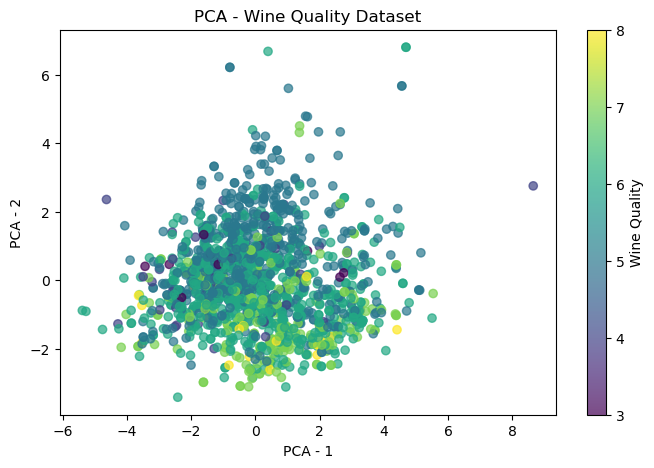

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.xlabel("PCA - 1")
plt.ylabel("PCA - 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()